# CLIP ViT-B/16 + CLIP ViT-L/14 + SigLIP 2 features + Attention MIL (whole video)

Notebook `03-clip_vitb16_mil.ipynb` described every 16-frame clip with the frozen image encoder of **CLIP ViT-B/16** and
classified each video, a bag of clips, with a **gated attention MIL** head: 5-fold CV accuracy **0.897**, ROC-AUC
**0.958** on the 350 labelled videos. This notebook keeps everything else of notebook 03 (same clips, same two views, same
MIL head and training, same TRAIN/VAL split, same 5 folds) and changes one thing:

**Backbone:** every clip is described by **three** frozen image–text encoders, and their clip features are concatenated
into one 2,432-d feature (512 + 768 + 1,152) that goes into the MIL head.

| backbone | from | trained on | image encoder | input | clip feature |
|---|---|---|---|---|---|
| CLIP ViT-B/16 (notebook 03's features) | OpenAI, 2021 | 400M image–text pairs | 86M params | 224×224 centre crop | 512-d |
| CLIP ViT-L/14 | OpenAI, 2021 | 400M image–text pairs | 304M params | 224×224 centre crop | 768-d |
| SigLIP 2 So400m/16 | Google, 2025 | WebLI: 10B images, 109 languages | ~400M params | 256×256 whole frame | 1,152-d |

Why three backbones and not one bigger one:
- **A bigger CLIP alone did not help.** An earlier experiment replaced B/16 by L/14 in notebook 03's pipeline: CV accuracy
  0.903 against 0.897, a difference of 2 of the 350 videos. Both CLIPs were trained on the same data and mostly make the
  **same mistakes** (24 of the 36 videos notebook 03 gets wrong were also wrong with L/14). Concatenating the B/16 and
  L/14 features did help (CV accuracy 0.914 in an earlier nested-CV experiment): the head can rely on whichever backbone
  recognises the event. The backbone ablation at the end of section 11 repeats both experiments with this notebook's
  features and notebook 03's protocol (L/14 alone 0.903, B/16 + L/14 0.917).
- **SigLIP 2 is a different family**, so its mistakes should overlap less with CLIP's: other training data, a sigmoid
  instead of a softmax image–text loss, and extra training objectives (captioning, self-distillation, masked prediction)
  that improve its local features. It is also much stronger on its own: ImageNet zero-shot accuracy 83.4 %, against
  68.3 % (B/16) and 75.5 % (L/14).
- **Field of view:** CLIP's preprocessing keeps the centre 224×224 of the frame resized to 299×224, so the left and right
  edges (25 % of the width) are never seen. SigLIP 2's own preprocessing resizes the **whole frame** to 256×256, so an
  event at the edge of the picture is still seen by one of the backbones.

As in notebook 03 the backbones are frozen and only the MIL head is trained: 297 training videos are far too few to
fine-tune an image encoder (notebook 03's fine-tuning attempt did not improve VAL).

Pipeline:
1. **Feature extraction (once):** frozen CLIP ViT-L/14 and SigLIP 2 on every 4th frame of every video; the B/16 features
   are reused from notebook 03's cache. All three use the same 16-frame clips as notebooks 02 and 03, so their clip
   features are concatenated clip by clip. Two views (the image and its mirror image) from one decode of the video, as in 03.
2. **Zero-shot baseline:** text prompts only, no training, with each of the three backbones.
3. **Part A:** attention-MIL head on the *same* TRAIN/VAL split as notebooks 02 and 03 → directly comparable numbers.
4. **Part B:** 5-fold cross-validation over all labelled videos (TRAIN + VAL) with notebook 03's folds. With only 53 VAL
   videos one video is ~1.9 % accuracy, so the cross-validated accuracy (350 videos) is the number to trust.
5. TEST predictions (Part A model and the 5-fold ensemble), anomaly timelines, comparison with notebooks 01–03 (with a
   video-by-video test against notebook 03, and what each backbone adds).

**Weights:** on the first run `transformers` downloads `openai/clip-vit-large-patch14` (~1.7 GB) and
`google/siglip2-so400m-patch16-256` (~4.2 GB) to `~/.cache/huggingface`. To use copies you downloaded yourself, set the
`model` entries of `BACKBONES` in section 1 to those folders.

## 1. Configuration — change paths here

In [2]:
import os

# ---------------- PATHS (edit these if you move the notebook / dataset) ----------------
DATASET_ROOT = "/home/haseebumer/content/data/UCF_Crimes_MINI"   # Videos/ + Anomaly_Detection_splits/
SPLITS_DIR   = os.path.join(DATASET_ROOT, "Anomaly_Detection_splits")
RUNS_DIR     = "./runs_ucf_fusionmil"
NB03_RUNS    = "./runs_ucf_clipmil"         # notebook 03's saved models, re-scored for the paired comparison (section 11)
PREV_RUNS    = {"01 R(2+1)D-18, sampled clips": "./runs_ucf_mini",      # for the comparison (skipped if missing)
                "02 R(2+1)D-18, whole video":   "./runs_ucf_fullvideo",
                "03 CLIP ViT-B/16":             "./runs_ucf_clipmil"}

# ---------------- BACKBONES (frozen; their clip features are concatenated in this order) ----------------
# model:        Hugging Face id (downloaded on first use) or a local folder
# feats:        feature cache, <view>/<category>/<video>.npy, (N_clips, dim) float16
# frame_stride: embed every frame_stride-th frame of a clip (1 = every frame); must divide CLIP_LEN
# preprocess:   "crop" = short side resized to img_size (bicubic), centre crop img_size x img_size (CLIP)
#               "full" = the whole frame resized to img_size x img_size (bilinear, no crop: SigLIP's own preprocessing)
BACKBONES = {
    "CLIP B/16": dict(model="openai/clip-vit-base-patch16", feats="./features_clip_vitb16",    # notebook 03's cache
                      frame_stride=1, img_size=224, preprocess="crop"),
    "CLIP L/14": dict(model="openai/clip-vit-large-patch14", feats="./features_clip_vitl14",
                      frame_stride=4, img_size=224, preprocess="crop"),
    "SigLIP 2":  dict(model="google/siglip2-so400m-patch16-256", feats="./features_siglip2_so400m",
                      frame_stride=4, img_size=256, preprocess="full"),
}

# ---------------- SPLITS ----------------
VAL_FRACTION = 0.15        # same stratified hold-out as notebooks 02 / 03 (same seed) -> Part A is directly comparable
N_FOLDS      = 5           # Part B: cross-validation over all labelled videos (TRAIN + VAL), same folds as notebook 03

# ---------------- FEATURE EXTRACTION (frozen image encoders) ----------------
# A video is cut into consecutive, non-overlapping 16-frame clips (last one padded), as in notebooks 02 / 03. The kept
# frames of a clip are embedded and their embeddings averaged -> one feature per clip and backbone. L/14 and SigLIP 2
# cost ~5-6x B/16 per frame, so they embed every 4th frame (frames 1/30 s apart are near-identical).
CLIP_LEN     = 16
EMBED_PER_SEGMENT = 512    # a video is decoded and sent to the GPU 512 embedded frames at a time
                           # (32 clips at frame_stride 1, 128 clips at frame_stride 4)
FRAME_BATCH  = 256         # frames per forward pass (lower it if the GPU runs out of memory)
NUM_WORKERS  = 8           # CPU decode processes, 1 FFmpeg thread each
PREFETCH     = 2
VIEWS        = {"center": False, "center_flip": True}   # view name -> horizontal flip. Train: a random view per video
                                                        # per epoch (augmentation). Eval: logits averaged over all views.
                                                        # (names as in notebook 03; for SigLIP 2 the view is the whole frame)

# ---------------- ZERO-SHOT BASELINE (text prompts, no training; the prompts of notebook 03) ----------------
ANOMALY_PROMPTS = [f"a CCTV image of {s}" for s in [
    "a person being abused", "police arresting a person", "a building on fire", "a person being assaulted",
    "a burglar breaking into a building", "an explosion", "people fighting", "a road accident", "an armed robbery",
    "a person shooting a gun", "a person shoplifting in a store", "a person stealing something", "vandalism"]]
NORMAL_PROMPTS = [f"a CCTV image of {s}" for s in [
    "people walking normally", "an empty street", "cars driving normally on a road", "people shopping in a store",
    "an empty room", "a quiet parking lot", "people standing and talking"]]
ZS_TOPK      = 8           # video score = mean anomaly probability of its 8 most anomalous clips (~4 s)
ZS_BACKBONE  = "SigLIP 2"  # whose zero-shot clip probabilities are drawn in the anomaly timelines (section 9)

# ---------------- ATTENTION-MIL HEAD (notebook 03's settings, unchanged) ----------------
HIDDEN       = 256         # clip embedding size after the temporal conv
ATTN_DIM     = 128         # size of the gated attention layer
DROPOUT      = 0.5
BATCH_VIDEOS = 8           # videos per optimizer step (videos have different lengths -> gradient accumulation)
EPOCHS       = 40
LR           = 3e-4
WEIGHT_DECAY = 1e-2

SEED = 42

assert all(CLIP_LEN % b["frame_stride"] == 0 for b in BACKBONES.values()), "frame_stride must divide CLIP_LEN"
os.makedirs(RUNS_DIR, exist_ok=True)
assert os.path.isdir(DATASET_ROOT), f"DATASET_ROOT not found: {DATASET_ROOT}"
assert os.path.isdir(SPLITS_DIR), f"SPLITS_DIR not found: {SPLITS_DIR}"

## 2. Imports and GPU setup

In [3]:
import random, time, copy, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from transformers import AutoModel, AutoTokenizer, AutoImageProcessor
import matplotlib.pyplot as plt
from scipy.stats import binomtest, rankdata
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold
from tqdm.auto import tqdm


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False                # the MIL head sees a different sequence length for every video;
                                                      # benchmark mode would re-tune the conv for each new length
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
AMP_DTYPE = torch.bfloat16

print("torch", torch.__version__, "| device:", device)
if device.type == "cuda":
    free, total = torch.cuda.mem_get_info()
    print(torch.cuda.get_device_name(0), f"| free {free/2**30:.1f} GB / {total/2**30:.1f} GB")

/home/haseebumer/anaconda3/envs/ml_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu130 | device: cuda
NVIDIA GeForce RTX 5080 | free 8.2 GB / 15.6 GB


## 3. Build the file lists (0 = NORMAL, 1 = ANOMALY; VAL is the same stratified hold-out as notebooks 02 and 03; TEST has no labels)

In [4]:
CLASSES = ["NORMAL", "ANOMALY"]
VIDEOS_DIR = os.path.join(DATASET_ROOT, "Videos")

def category(path):
    """Folder name of the video, e.g. 'Robbery' or 'Training_Normal_Videos_Anomaly'."""
    return os.path.basename(os.path.dirname(path))

def read_split(fname, labelled=True):
    """labelled=False: label is -1 and is never used (TEST is treated like unseen real-world data)."""
    items = []
    for line in open(os.path.join(SPLITS_DIR, fname)):
        rel = line.strip()
        if not rel:
            continue
        path = os.path.join(VIDEOS_DIR, rel)
        assert os.path.isfile(path), f"missing video: {path}"
        items.append((path, (0 if "Normal" in category(path) else 1) if labelled else -1))
    return items


train_all = read_split("Anomaly_Train.txt")
test_items = read_split("Anomaly_Test.txt", labelled=False)
train_items, val_items = train_test_split(train_all, test_size=VAL_FRACTION, random_state=SEED,
                                          stratify=[category(p) for p, _ in train_all])
train_items, val_items = sorted(train_items), sorted(val_items)

# All labelled videos in one list: Part A uses TRAIN_IDX / VAL_IDX, Part B splits all of them into folds.
LAB_ITEMS = train_items + val_items
TRAIN_IDX = np.arange(len(train_items))
VAL_IDX   = np.arange(len(train_items), len(LAB_ITEMS))
Y_LAB     = torch.tensor([float(l) for _, l in LAB_ITEMS], device=device)

for name, it in [("TRAIN", train_items), ("VAL", val_items)]:
    labs = [l for _, l in it]
    print(f"{name:5s}: {len(it):5d} videos | anomaly {sum(labs):4d} | normal {len(labs)-sum(labs):4d}")
print(f"TEST : {len(test_items):5d} videos | unlabelled (predictions only)")

TRAIN:   297 videos | anomaly  165 | normal  132
VAL  :    53 videos | anomaly   29 | normal   24
TEST :    84 videos | unlabelled (predictions only)


## 4. Feature extraction — frozen CLIP ViT-L/14 and SigLIP 2, every 4th frame, cached to disk

- Same clips as notebooks 02 and 03: consecutive non-overlapping 16-frame clips, the last clip padded by repeating the last
  frame. The three backbones see exactly the same clips, so their features line up clip by clip.
- **CLIP ViT-L/14:** each embedded frame is resized (short side 224, bicubic), centre-cropped to 224×224 and normalised
  with CLIP's statistics, exactly like B/16 in notebook 03 → projected 768-d embedding (the image–text space),
  L2-normalised.
- **SigLIP 2 So400m/16:** the whole frame is resized to 256×256 (bilinear, antialiased, no crop) and normalised to
  [−1, 1], as in SigLIP's own preprocessing → 1,152-d output of its attention-pooling head (the image–text space),
  L2-normalised.
- **Every 4th frame** of a clip is embedded (frames 0, 4, 8, 12): L/14 and SigLIP 2 cost ~5–6× B/16 per frame, and
  frames 1/30 s apart are near-identical, so the mean of 4 frames is almost the mean of 16. The 4 embeddings of a clip are
  averaged into one clip feature.
- **CLIP ViT-B/16:** notebook 03's cached features (every frame) are reused. If `features_clip_vitb16/` is missing, they
  are re-extracted with notebook 03's settings.
- The backbones are **not** fine-tuned, so the features contain no information about our labels and can be reused for
  every fold of Part B.
- Each video is decoded **once per backbone**: the mirror view is made on the GPU from the same frames.
- Videos are streamed in segments of `EMBED_PER_SEGMENT` embedded frames. The clip features of a video are saved as
  `<feats>/<view>/<category>/<video>.npy` (float16).
- Extraction is **resumable**: videos whose `.npy` files already exist are skipped, so this cell is fast after the first run.
- The text embeddings of the zero-shot prompts are computed with each backbone's own text encoder in the same cell and
  saved to `<feats>/text_embeddings.pt`.

Cost: ~3.2M frames decoded and ~0.8M frames × 2 views embedded per backbone, about **68 min** for L/14 and
**77 min** for SigLIP 2 on the RTX 5080 (measured). B/16 from scratch (every frame) would take another ~1 h.

In [5]:
def open_video(path):
    # 1 decode thread per video: the default (16) costs ~5x more RAM per open video and,
    # summed over all workers, oversubscribes the CPU.
    return cv2.VideoCapture(path, cv2.CAP_FFMPEG, [cv2.CAP_PROP_N_THREADS, 1])


def frame_count(path):
    cap = open_video(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return n


def video_fps(path):
    cap = open_video(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    return fps if fps and fps > 0 else 30.0


def resize_crop(fr, size):
    """BGR frame -> uint8 (size, size, 3) RGB: short side resized to `size` (bicubic, as CLIP), centre crop."""
    h, w = fr.shape[:2]
    s = size / min(h, w)
    nh, nw = max(size, round(h * s)), max(size, round(w * s))
    fr = cv2.resize(fr, (nw, nh), interpolation=cv2.INTER_CUBIC)
    y, x = (nh - size) // 2, (nw - size) // 2
    return cv2.cvtColor(fr[y:y + size, x:x + size], cv2.COLOR_BGR2RGB)


def full_frame(fr, size):
    """BGR frame -> uint8 (H, W, 3) RGB, the whole frame. It is resized to size x size on the GPU (embed_frames) with
       the antialiased bilinear filter of SigLIP's image processor."""
    return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)


PREPROCESS = {"crop": resize_crop, "full": full_frame}


def read_frames(path, start, count, bb):
    """Decodes `count` consecutive frames from frame `start` (count=None: up to the end of the video) and keeps every
       frame_stride-th one, preprocessed for backbone `bb` (`start` is a multiple of CLIP_LEN, so the kept frames line
       up with the clips). Returns (list of uint8 (H, W, 3) RGB arrays, number of frames decoded)."""
    prep, stride, size = PREPROCESS[bb["preprocess"]], bb["frame_stride"], bb["img_size"]
    cap = open_video(path)
    if start > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)

    def grab():
        frames, n = [], 0
        while count is None or n < count:
            if not cap.grab():
                break
            if n % stride == 0:                       # skipped frames are only grabbed, never converted
                ok, fr = cap.retrieve()
                if not ok:
                    break
                frames.append(prep(fr, size))
            n += 1
        return frames, n

    frames, n = grab()
    if n == 0 and start > 0:                # seek failed -> reopen and step through the frames before `start`
        cap.release(); cap = open_video(path)
        for _ in range(start):
            if not cap.grab():
                break
        frames, n = grab()
    cap.release()
    return frames, n


class SegmentDataset(Dataset):
    """One item = one segment of one video: up to EMBED_PER_SEGMENT kept frames of consecutive 16-frame clips, returned
       as (n_clips * frames_per_clip, H, W, 3) uint8 frames in time order. The segments of a video together cover every
       one of its frames. Keys (vid, seg) come from SegmentSampler."""
    def __init__(self, items, bb):
        self.items, self.bb = items, bb
        self.frames_per_clip = CLIP_LEN // bb["frame_stride"]                       # frames embedded per clip
        self.seg_frames = CLIP_LEN * (EMBED_PER_SEGMENT // self.frames_per_clip)    # frames decoded per segment
        self.n_frames = [frame_count(p) for p, _ in items]
        self.n_segs = [max(1, -(-n // self.seg_frames)) for n in self.n_frames]

    def __len__(self):
        return sum(self.n_segs)

    def __getitem__(self, key):
        vid, seg = key
        path, size = self.items[vid][0], self.bb["img_size"]
        last = seg == self.n_segs[vid] - 1
        frames, n_read = read_frames(path, seg * self.seg_frames, None if last else self.seg_frames, self.bb)
        if not frames and seg == 0:
            print(f"WARNING: could not decode {path}")
            frames, n_read = [np.zeros((size, size, 3), np.uint8)], 1
        n_clips = -(-n_read // CLIP_LEN)
        if frames:
            frames += [frames[-1]] * (n_clips * self.frames_per_clip - len(frames))   # pad the last clip
        x = np.stack(frames) if frames else np.zeros((0, size, size, 3), np.uint8)
        return torch.from_numpy(x), n_clips, vid, last


class SegmentSampler(Sampler):
    """Yields the segments of video 0, then video 1, ... in order (the DataLoader keeps this order with many workers)."""
    def __init__(self, ds):
        self.ds = ds

    def __len__(self):
        return sum(self.ds.n_segs)

    def __iter__(self):
        for v in range(len(self.ds.items)):
            for s in range(self.ds.n_segs[v]):
                yield (v, s)


def worker_init(_):
    cv2.setNumThreads(1)                     # one decode thread per worker; parallelism comes from workers


def load_backbone(bb):
    """Frozen image-text model (CLIP or SigLIP), its tokenizer and its pixel normalisation (mean, std)."""
    model = AutoModel.from_pretrained(bb["model"], attn_implementation="sdpa").to(device).eval()
    proc = AutoImageProcessor.from_pretrained(bb["model"])
    norm = (torch.tensor(proc.image_mean, device=device).view(1, 3, 1, 1),
            torch.tensor(proc.image_std, device=device).view(1, 3, 1, 1))
    return model, AutoTokenizer.from_pretrained(bb["model"]), norm


def image_embedding(model, x):
    """Embedding in the joint image-text space. CLIP: CLS token -> visual projection. SigLIP: attention-pooling head."""
    e = model.vision_model(pixel_values=x).pooler_output
    return model.visual_projection(e) if model.config.model_type == "clip" else e


@torch.no_grad()
def embed_frames(model, bb, norm, x):
    """(F, H, W, 3) uint8 frames -> {view: (F, dim) L2-normalised image embeddings of backbone `bb`}."""
    x = x.to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
    if bb["preprocess"] == "full":                           # SigLIP: the whole frame -> img_size x img_size
        x = F.interpolate(x, size=(bb["img_size"], bb["img_size"]), mode="bilinear", antialias=True,
                          align_corners=False)
    x = (x - norm[0]) / norm[1]
    out = {view: [] for view in VIEWS}
    for b in range(0, len(x), FRAME_BATCH):
        xb = x[b:b + FRAME_BATCH]
        for view, flip in VIEWS.items():
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                e = image_embedding(model, xb.flip(-1) if flip else xb)
            out[view].append(F.normalize(e.float(), dim=-1))
    return {view: torch.cat(e) for view, e in out.items()}


@torch.no_grad()
def embed_text(model, tokenizer, prompts):
    """Prompts -> (P, dim) L2-normalised text embeddings in the joint image-text space."""
    if model.config.model_type == "clip":
        tok = tokenizer(prompts, padding=True, return_tensors="pt").to(device)
        e = model.text_projection(model.text_model(input_ids=tok["input_ids"],
                                                   attention_mask=tok["attention_mask"]).pooler_output)
    else:                                            # SigLIP: padded to 64 tokens, no attention mask (as in training)
        tok = tokenizer(prompts, padding="max_length", max_length=64, return_tensors="pt").to(device)
        e = model.text_model(input_ids=tok["input_ids"]).pooler_output
    return F.normalize(e.float(), dim=-1)


def feat_path(path, bb, view):
    rel = os.path.relpath(path, VIDEOS_DIR)
    return os.path.join(bb["feats"], view, os.path.splitext(rel)[0] + ".npy")


def uncached(items, bb):
    return [it for it in items if not all(os.path.exists(feat_path(it[0], bb, v)) for v in VIEWS)]


@torch.no_grad()
def extract_features(model, bb, norm, items):
    """Saves the (N_clips, dim) float16 clip features of every view of every video in `items` that is not cached yet."""
    todo = uncached(items, bb)
    print(f"{len(items) - len(todo)} videos cached, {len(todo)} to extract")
    if not todo:
        return
    ds = SegmentDataset(todo, bb)
    print(f"{sum(ds.n_frames):,} frames to decode, {sum(ds.n_frames) // bb['frame_stride']:,} to embed")
    loader = DataLoader(ds, sampler=SegmentSampler(ds), batch_size=None, num_workers=NUM_WORKERS,
                        pin_memory=True, worker_init_fn=worker_init,
                        prefetch_factor=PREFETCH if NUM_WORKERS > 0 else None)
    chunks = {view: [] for view in VIEWS}
    for x, n_clips, vid, last in tqdm(loader, desc="extract"):
        if n_clips:
            for view, e in embed_frames(model, bb, norm, x).items():
                chunks[view].append(e.view(n_clips, ds.frames_per_clip, -1).mean(1).cpu())   # frame mean per clip
        if last:
            for view in VIEWS:
                out = feat_path(todo[vid][0], bb, view)
                os.makedirs(os.path.dirname(out), exist_ok=True)
                np.save(out[:-4] + ".tmp.npy", torch.cat(chunks[view]).half().numpy())
                os.replace(out[:-4] + ".tmp.npy", out)            # atomic: an interrupted run never leaves a broken file
            chunks = {view: [] for view in VIEWS}


for name, bb in BACKBONES.items():
    text_file = os.path.join(bb["feats"], "text_embeddings.pt")
    if not uncached(LAB_ITEMS + test_items, bb) and os.path.exists(text_file):
        print(f"{name}: {len(LAB_ITEMS + test_items)} videos cached in {bb['feats']}, 0 to extract")
        continue
    model, tokenizer, norm = load_backbone(bb)
    os.makedirs(bb["feats"], exist_ok=True)
    text = {"anomaly": embed_text(model, tokenizer, ANOMALY_PROMPTS).cpu(),
            "normal": embed_text(model, tokenizer, NORMAL_PROMPTS).cpu(),
            "logit_scale": model.logit_scale.exp().item()}
    torch.save(text, text_file)
    print(f"{name}: image encoder {sum(p.numel() for p in model.vision_model.parameters()) / 1e6:.1f}M params, "
          f"embedding dim {text['anomaly'].shape[1]}")
    t0 = time.time()
    extract_features(model, bb, norm, LAB_ITEMS + test_items)
    print(f"{name}: feature extraction done in {(time.time() - t0) / 60:.1f} min")
    del model
    torch.cuda.empty_cache()

CLIP B/16: 434 videos cached in ./features_clip_vitb16, 0 to extract
CLIP L/14: 434 videos cached in ./features_clip_vitl14, 0 to extract
SigLIP 2: 434 videos cached in ./features_siglip2_so400m, 0 to extract


### Load the cached features onto the GPU (float16) and concatenate the three backbones clip by clip

In [6]:
def load_feats(items):
    """{view: [ (N_clips, D_FEAT) float16 tensor on the GPU, one per video ]}: the clip features of all backbones,
       concatenated in the order of BACKBONES."""
    out = {view: [] for view in VIEWS}
    for view in VIEWS:
        for p, _ in items:
            parts = [np.load(feat_path(p, bb, view)) for bb in BACKBONES.values()]
            assert len({len(f) for f in parts}) == 1, f"the backbones have different clip counts for {p}"
            out[view].append(torch.from_numpy(np.concatenate(parts, axis=1)).to(device))
    return out


F_LAB  = load_feats(LAB_ITEMS)
F_TEST = load_feats(test_items)
D_FEAT = F_LAB["center"][0].shape[1]

# the columns of every backbone in the fused features
DIMS = {name: np.load(feat_path(LAB_ITEMS[0][0], bb, "center"), mmap_mode="r").shape[1] for name, bb in BACKBONES.items()}
ends = np.cumsum(list(DIMS.values()))
SLICES = {name: slice(int(e) - d, int(e)) for (name, d), e in zip(DIMS.items(), ends)}
print("fused clip feature:", " + ".join(f"{name} {d}" for name, d in DIMS.items()), f"= {D_FEAT}-d")

for name, feats in [("TRAIN", [F_LAB["center"][i] for i in TRAIN_IDX]), ("VAL", [F_LAB["center"][i] for i in VAL_IDX]),
                    ("TEST", F_TEST["center"])]:
    n = np.array([len(f) for f in feats])
    print(f"{name:5s}: {n.sum():6d} clips | clips/video min {n.min()} median {int(np.median(n))} max {n.max()}")

fused clip feature: CLIP B/16 512 + CLIP L/14 768 + SigLIP 2 1152 = 2432-d
TRAIN: 149747 clips | clips/video min 13 median 140 max 39252
VAL  :  26299 clips | clips/video min 21 median 170 max 7910
TEST :  22643 clips | clips/video min 14 median 105 max 6750


## 5. Plotting and metric helpers

In [7]:
def plot_history(hist, title, best_ep=None, save_name=None, extra_marks=None):
    """hist values may be lists (one run) or arrays of shape (folds, epochs) (mean ± std is drawn)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, key, name in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy"), (axes[2], "auc", "ROC-AUC")]:
        for split, marker in [("train", "o-"), ("val", "s-")]:
            if f"{split}_{key}" not in hist:
                continue
            v = np.atleast_2d(np.array(hist[f"{split}_{key}"]))
            ep = np.arange(1, v.shape[1] + 1)
            m, s = v.mean(0), v.std(0)
            ax.plot(ep, m, marker, ms=3, label=f"{split.capitalize()} {name.lower()}")
            if len(v) > 1:
                ax.fill_between(ep, m - s, m + s, alpha=0.2)
        if best_ep:
            ax.axvline(best_ep, color="red", ls="--", lw=1.5, label=f"Selected epoch ({best_ep})")
        for ep_m, lab in (extra_marks or []):
            ax.axvline(ep_m, color="green", ls=":", lw=1.5, label=lab)
        ax.set_xlabel("Epoch"); ax.set_ylabel(name); ax.set_title(f"{title} — {name}")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(RUNS_DIR, save_name), dpi=150)
    plt.show()


def sigmoid(z):
    return 1 / (1 + np.exp(-np.asarray(z, np.float64)))


def metric_dict(y, probs):
    pred = (probs >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, probs) if len(set(y)) == 2 else float("nan")}


def item_metrics(probs, items):
    return metric_dict(np.array([l for _, l in items]), probs)


def report(probs, items, split_name, stage_name, train_m=None, train_name="TRAIN"):
    """train_m: metrics on the training videos, shown as an extra row of the table (the classification report,
       per-category accuracy and confusion matrix are for `items` only)."""
    y = np.array([l for _, l in items])
    pred = (probs >= 0.5).astype(int)
    m = metric_dict(y, probs)
    print(f"===== {stage_name} | {split_name} ({len(items)} videos, whole video) =====")
    rows = ([train_m] if train_m else []) + [m]
    print(pd.DataFrame(rows, index=([train_name] if train_m else []) + [split_name]).round(4).to_string())
    print(classification_report(y, pred, target_names=CLASSES, digits=4, zero_division=0))

    df = pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in items],
                       "category": [category(p) for p, _ in items],
                       "label": np.array(CLASSES)[y], "anomaly_prob": probs.round(4),
                       "prediction": np.array(CLASSES)[pred]})
    df["correct"] = df["label"] == df["prediction"]
    print("Per-category accuracy:")
    print(df.groupby("category")["correct"].agg(["mean", "size"]).rename(columns={"mean": "acc", "size": "videos"})
            .round(3).to_string(), "\n")

    cm = confusion_matrix(y, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], CLASSES); ax.set_yticks([0, 1], CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{stage_name} — {split_name}")
    plt.tight_layout(); plt.show()
    return m

## 6. Zero-shot baseline — text prompts, no training, with each backbone

As in notebook 03: each clip feature is compared with the text embeddings of the anomaly prompts (one per UCF-Crime
category) and the normal prompts, here with each backbone's own text encoder. A softmax over all prompts gives a per-clip
anomaly probability (the sum over the anomaly prompts). The video score is the mean of its `ZS_TOPK` most anomalous clips,
averaged over both views.

Without training the score is not calibrated, so 0.5 is not a meaningful threshold. The threshold is the one with the
best accuracy on the **TRAIN** videos, and is then applied to VAL. ROC-AUC does not depend on the threshold.
This shows how much each backbone already "knows" before any training. The CLIP B/16 rows are notebook 03's zero-shot
baseline (same features, same prompts).

CLIP B/16 zero-shot threshold (best TRAIN accuracy): 0.8703 | TRAIN acc 0.7643 | TRAIN auc 0.8211
CLIP L/14 zero-shot threshold (best TRAIN accuracy): 0.9035 | TRAIN acc 0.7576 | TRAIN auc 0.8042
SigLIP 2 zero-shot threshold (best TRAIN accuracy): 0.9958 | TRAIN acc 0.7441 | TRAIN auc 0.8194

                           accuracy  precision  recall      f1  roc_auc
CLIP B/16 zero-shot TRAIN    0.7643     0.7684  0.8242  0.7953   0.8211
                    VAL      0.8302     0.8571  0.8276  0.8421   0.8261
CLIP L/14 zero-shot TRAIN    0.7576     0.7688  0.8061  0.7870   0.8042
                    VAL      0.8113     0.8276  0.8276  0.8276   0.8520
SigLIP 2 zero-shot  TRAIN    0.7441     0.7633  0.7818  0.7725   0.8194
                    VAL      0.8113     0.9130  0.7241  0.8077   0.8592 

===== SigLIP 2 zero-shot | VAL (53 videos, whole video) =====
       accuracy  precision  recall      f1  roc_auc
TRAIN    0.7441     0.7633  0.7818  0.7725   0.8194
VAL      0.8113     0.9130  0.7241

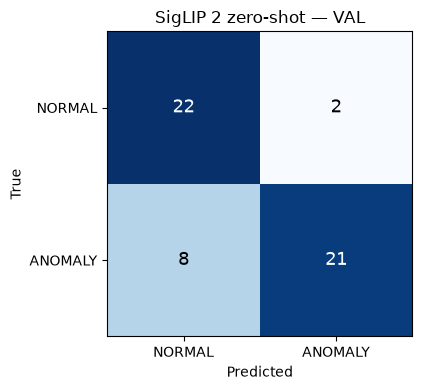

In [8]:
TEXT = {}
for name, bb in BACKBONES.items():
    t = torch.load(os.path.join(bb["feats"], "text_embeddings.pt"))
    assert len(t["anomaly"]) == len(ANOMALY_PROMPTS) and len(t["normal"]) == len(NORMAL_PROMPTS)
    TEXT[name] = {"emb": torch.cat([t["anomaly"], t["normal"]]).to(device),   # anomaly prompts first
                  "scale": t["logit_scale"]}
N_ANOM_PROMPTS = len(ANOMALY_PROMPTS)


def zs_clip_probs(x, name=ZS_BACKBONE):
    """(N_clips, D_FEAT) fused clip features -> (N_clips,) zero-shot anomaly probability of every clip, from backbone
       `name`: its part of the features against its own text embeddings."""
    logits = TEXT[name]["scale"] * F.normalize(x[:, SLICES[name]].float(), dim=-1) @ TEXT[name]["emb"].T
    return logits.softmax(-1)[:, :N_ANOM_PROMPTS].sum(-1)


@torch.no_grad()
def zs_video_scores(feats, idx, name):
    out = []
    for i in idx:
        p = torch.stack([zs_clip_probs(feats[v][i], name) for v in VIEWS]).mean(0)
        out.append(p.topk(min(ZS_TOPK, len(p))).values.mean().item())
    return np.array(out)


def prob_to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


y_train = Y_LAB[TRAIN_IDX].cpu().numpy().astype(int)
metrics, zs_val_probs = {}, {}
for name in BACKBONES:
    zs_train, zs_val = zs_video_scores(F_LAB, TRAIN_IDX, name), zs_video_scores(F_LAB, VAL_IDX, name)
    cands = np.unique(zs_train)
    zs_thr = cands[np.argmax([((zs_train >= t) == y_train).mean() for t in cands])]
    print(f"{name} zero-shot threshold (best TRAIN accuracy): {zs_thr:.4f} | "
          f"TRAIN acc {((zs_train >= zs_thr) == y_train).mean():.4f} | TRAIN auc {roc_auc_score(y_train, zs_train):.4f}")
    # shift so the TRAIN threshold maps to 0.5 (a monotone transform: ROC-AUC is unchanged)
    metrics[(f"{name} zero-shot", "TRAIN")] = item_metrics(sigmoid(prob_to_logit(zs_train) - prob_to_logit(zs_thr)),
                                                           train_items)
    zs_val_probs[name] = sigmoid(prob_to_logit(zs_val) - prob_to_logit(zs_thr))
    metrics[(f"{name} zero-shot", "VAL")] = item_metrics(zs_val_probs[name], val_items)

print("\n" + pd.DataFrame(metrics).T.round(4).to_string(), "\n")
_ = report(zs_val_probs[ZS_BACKBONE], val_items, "VAL", f"{ZS_BACKBONE} zero-shot",
           train_m=metrics[(f"{ZS_BACKBONE} zero-shot", "TRAIN")])

## 7. Model: gated attention MIL over the fused clip features of a video

Notebook 03's head, unchanged. Only its input is new: for every clip the concatenation
$x_i = [\,x_i^{\mathrm{B/16}} \mid x_i^{\mathrm{L/14}} \mid x_i^{\mathrm{SigLIP\,2}}\,]$ (2,432-d). The LayerNorm (with a
learned gain per dimension) and the temporal conv learn how much to rely on each backbone.

For a video with clip features $x_1 \dots x_N$:
1. **Temporal conv** (kernel 3): $h_i$ mixes each clip with its neighbours. An event spans several 16-frame clips, and
   CLIP features carry no motion, so this is where short-range temporal context comes from.
2. **Gated attention**: $a_i = \mathrm{softmax}_i\big(w^\top(\tanh(V h_i) \odot \sigma(U h_i))\big)$, with $\sum_i a_i = 1$.
3. **Video logit** = $\mathrm{classifier}\big(\sum_i a_i h_i\big)$ = $\sum_i a_i \cdot \mathrm{classifier}(h_i)$, an
   attention-weighted average of **per-clip anomaly logits**. Mean pooling (notebook 02) is the special case $a_i = 1/N$.
   Here the model can put almost all the weight on the few clips that contain the event.

The loss is one BCE per video, because only video labels exist.

In [9]:
class AttentionMIL(nn.Module):
    """Gated attention MIL (Ilse et al., 2018) with a temporal conv in front.
       Input: (N_clips, d_in) features of one video.
       Output: video logit (1,), attention weights (N_clips,) summing to 1, per-clip anomaly logits (N_clips,)."""
    def __init__(self, d_in=D_FEAT, hidden=HIDDEN, attn_dim=ATTN_DIM, p_drop=DROPOUT):
        super().__init__()
        self.norm = nn.LayerNorm(d_in)
        self.embed = nn.Sequential(nn.Conv1d(d_in, hidden, kernel_size=3, padding=1), nn.GELU(), nn.Dropout(p_drop))
        self.attn_v = nn.Linear(hidden, attn_dim)
        self.attn_u = nn.Linear(hidden, attn_dim)
        self.attn_w = nn.Linear(attn_dim, 1)
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.embed(self.norm(x.float()).T[None])[0].T                    # (N, hidden)
        a = self.attn_w(torch.tanh(self.attn_v(h)) * torch.sigmoid(self.attn_u(h))).squeeze(1)
        a = torch.softmax(a, dim=0)                                         # (N,)
        return self.classifier(a @ h), a, self.classifier(h).squeeze(1)


def make_criterion(idx):
    """BCE with pos_weight = #normal / #anomaly of the training videos `idx` (same balancing as notebook 02)."""
    n_pos = Y_LAB[idx].sum()
    return nn.BCEWithLogitsLoss(pos_weight=((len(idx) - n_pos) / n_pos).view(1))


def video_logits(model, feats, idx):
    """One logit per video: the model's video logit averaged over all views (test-time augmentation)."""
    return torch.cat([torch.stack([model(feats[v][i])[0] for v in VIEWS]).mean(0) for i in idx])


def train_epoch(model, optimizer, crit, idx, feats=None):
    """One pass over the training videos in random order, one random view per video, BATCH_VIDEOS videos per step.
       feats: the clip features to train on (default: the fused features F_LAB)."""
    feats = F_LAB if feats is None else feats
    model.train()
    optimizer.zero_grad(set_to_none=True)
    order = np.random.permutation(idx)
    losses, correct = [], 0
    for n, i in enumerate(order, 1):
        logit = model(feats[random.choice(list(VIEWS))][i])[0]
        loss = crit(logit, Y_LAB[i:i + 1])
        (loss / BATCH_VIDEOS).backward()
        losses.append(loss.item())
        correct += int((logit.item() > 0) == bool(Y_LAB[i]))
        if n % BATCH_VIDEOS == 0 or n == len(order):
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
    return float(np.mean(losses)), correct / len(order)


@torch.no_grad()
def evaluate(model, crit, idx, feats=None):
    """loss, accuracy, ROC-AUC and logits on the labelled videos `idx` (all views averaged, no dropout)."""
    feats = F_LAB if feats is None else feats
    model.eval()
    logits = video_logits(model, feats, idx)
    y = Y_LAB[idx]
    acc = ((logits > 0).float() == y).float().mean().item()
    return crit(logits, y).item(), acc, roc_auc_score(y.cpu().numpy(), logits.cpu().numpy()), logits.cpu().numpy()


def fit(train_idx, val_idx, epochs=EPOCHS, select_best=False, seed=SEED, verbose=True, feats=None):
    """Trains a new AttentionMIL head on `train_idx`, evaluating on `val_idx` after every epoch.
       select_best=True: returns the weights of the epoch with the lowest val loss (smoother than accuracy on 53 videos).
       select_best=False: returns the last epoch (used for cross-validation, where no fold looks at its own val set).
       feats: the clip features to use (default: the fused features; section 11 also trains on subsets of the backbones)."""
    feats = F_LAB if feats is None else feats
    seed_everything(seed)
    model = AttentionMIL(d_in=feats["center"][0].shape[1]).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    crit = make_criterion(train_idx)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_auc"]}
    best_loss, best_state, best_ep = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, optimizer, crit, train_idx, feats)
        scheduler.step()
        va_loss, va_acc, va_auc, _ = evaluate(model, crit, val_idx, feats)
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc, va_auc]):
            hist[k].append(v)
        flag = ""
        if select_best and va_loss < best_loss:
            best_loss, best_state, best_ep = va_loss, copy.deepcopy(model.state_dict()), ep
            flag = "  <- best"
        if verbose:
            print(f"epoch {ep:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f} auc {va_auc:.4f} | {time.time()-t0:.1f}s{flag}")
    if select_best:
        model.load_state_dict(best_state)
        if verbose:
            print(f"Loaded best epoch {best_ep} (val loss {best_loss:.4f})")
    model.eval()
    return model, hist, best_ep


@torch.no_grad()
def predict_test(models, stage_name, file_tag):
    """Anomaly probability of every TEST video: sigmoid of the video logit averaged over views and over `models`."""
    logits = np.mean([video_logits(m.eval(), F_TEST, range(len(test_items))).cpu().numpy() for m in models], axis=0)
    probs = sigmoid(logits)
    df = pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in test_items],
                       "anomaly_prob": probs.round(4),
                       "prediction": np.where(probs >= 0.5, CLASSES[1], CLASSES[0])})
    out = os.path.join(RUNS_DIR, f"test_predictions_{file_tag}.csv")
    df.to_csv(out, index=False)
    print(f"===== {stage_name} | TEST ({len(df)} videos) -> {out} =====")
    print(df["prediction"].value_counts().to_string())
    return df


MODEL_NAME = "B/16 + L/14 + SigLIP 2 + Attention MIL"
print("trainable params:", sum(p.numel() for p in AttentionMIL().parameters()))

trainable params: 1939074


## 8. Part A — fused features + Attention MIL on the same TRAIN / VAL split as notebooks 02 and 03

Trains in seconds per epoch because the features are cached. As in notebook 03, the epoch with the lowest VAL loss is kept
(notebook 02 kept the epoch with the highest VAL accuracy; the loss is smoother on 53 videos).

In [10]:
model_a, hist_a, best_ep_a = fit(TRAIN_IDX, VAL_IDX, select_best=True)
torch.save({"model": model_a.state_dict(), "epoch": best_ep_a}, os.path.join(RUNS_DIR, "fusionmil_best.pt"))

epoch  1/40 | train loss 0.2981 acc 0.8586 | val loss 0.1688 acc 0.9245 auc 0.9799 | 1.7s  <- best
epoch  2/40 | train loss 0.1371 acc 0.9428 | val loss 0.2179 acc 0.9057 auc 0.9842 | 0.9s
epoch  3/40 | train loss 0.0611 acc 0.9731 | val loss 0.1633 acc 0.9434 auc 0.9856 | 0.9s  <- best
epoch  4/40 | train loss 0.0363 acc 0.9966 | val loss 0.1773 acc 0.9434 auc 0.9828 | 0.9s
epoch  5/40 | train loss 0.0227 acc 1.0000 | val loss 0.1978 acc 0.9245 auc 0.9799 | 0.9s
epoch  6/40 | train loss 0.0119 acc 1.0000 | val loss 0.2306 acc 0.9245 auc 0.9813 | 0.9s
epoch  7/40 | train loss 0.0056 acc 1.0000 | val loss 0.1812 acc 0.9434 auc 0.9856 | 0.9s
epoch  8/40 | train loss 0.0026 acc 1.0000 | val loss 0.2150 acc 0.9434 auc 0.9842 | 0.9s
epoch  9/40 | train loss 0.0023 acc 1.0000 | val loss 0.2120 acc 0.9245 auc 0.9842 | 0.9s
epoch 10/40 | train loss 0.0015 acc 1.0000 | val loss 0.2130 acc 0.9245 auc 0.9842 | 0.9s
epoch 11/40 | train loss 0.0010 acc 1.0000 | val loss 0.2273 acc 0.9434 auc 0.9842

### Part A — accuracy, loss & ROC-AUC curves

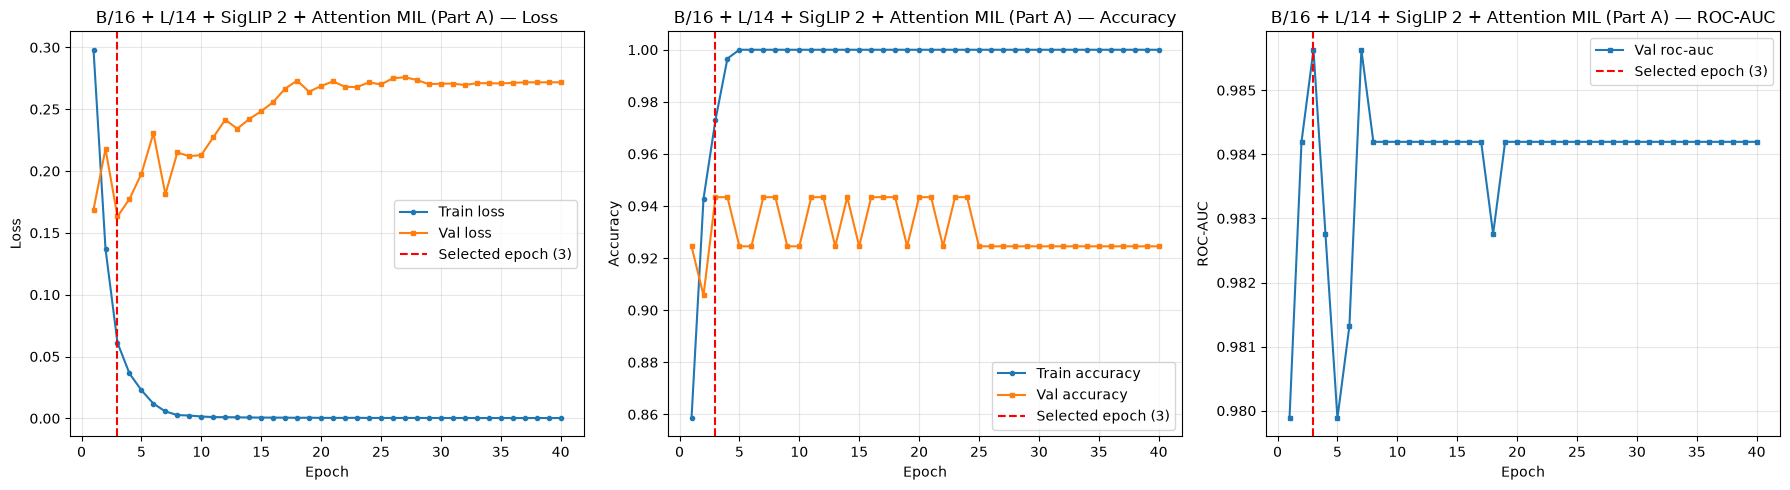

In [11]:
plot_history(hist_a, f"{MODEL_NAME} (Part A)", best_ep=best_ep_a, save_name="curves_part_a.png")

### Part A — accuracy, precision, recall, F1, ROC-AUC (VAL) + TEST predictions

===== B/16 + L/14 + SigLIP 2 + Attention MIL | VAL (53 videos, whole video) =====
       accuracy  precision  recall      f1  roc_auc
TRAIN    0.9966     0.9940   1.000  0.9970   0.9998
VAL      0.9434     0.9643   0.931  0.9474   0.9856
              precision    recall  f1-score   support

      NORMAL     0.9200    0.9583    0.9388        24
     ANOMALY     0.9643    0.9310    0.9474        29

    accuracy                         0.9434        53
   macro avg     0.9421    0.9447    0.9431        53
weighted avg     0.9442    0.9434    0.9435        53

Per-category accuracy:
                                  acc  videos
category                                     
Abuse                           0.500       2
Arrest                          1.000       1
Arson                           1.000       1
Assault                         1.000       2
Burglary                        1.000       3
Explosion                       1.000       2
Fighting                        1.000       

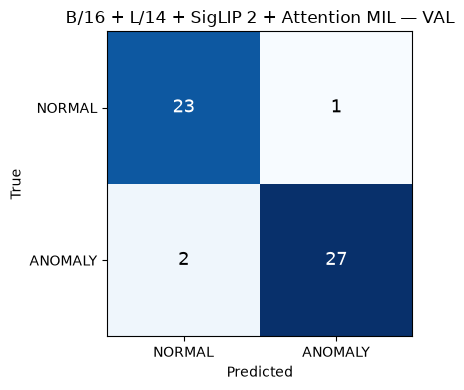

===== B/16 + L/14 + SigLIP 2 + Attention MIL | TEST (84 videos) -> ./runs_ucf_fusionmil/test_predictions_fusionmil.csv =====
prediction
NORMAL     48
ANOMALY    36


In [12]:
_, _, _, train_logits_a = evaluate(model_a, make_criterion(TRAIN_IDX), TRAIN_IDX)
_, _, _, val_logits_a = evaluate(model_a, make_criterion(TRAIN_IDX), VAL_IDX)
metrics[(MODEL_NAME, "TRAIN")] = item_metrics(sigmoid(train_logits_a), train_items)
metrics[(MODEL_NAME, "VAL")] = report(sigmoid(val_logits_a), val_items, "VAL", MODEL_NAME,
                                      train_m=metrics[(MODEL_NAME, "TRAIN")])
test_pred_a = predict_test([model_a], MODEL_NAME, "fusionmil")

## 9. Anomaly timelines — where in the video does the model look?

For some VAL videos, plotted against time in the video:
- the attention weight of every clip (how much it decides the video, scaled so the largest is 1);
- the clip's own anomaly probability from the trained head;
- the clip's zero-shot anomaly probability (SigLIP 2 with the text prompts, no training).

The model was never told where the events are. It only received one label per video.

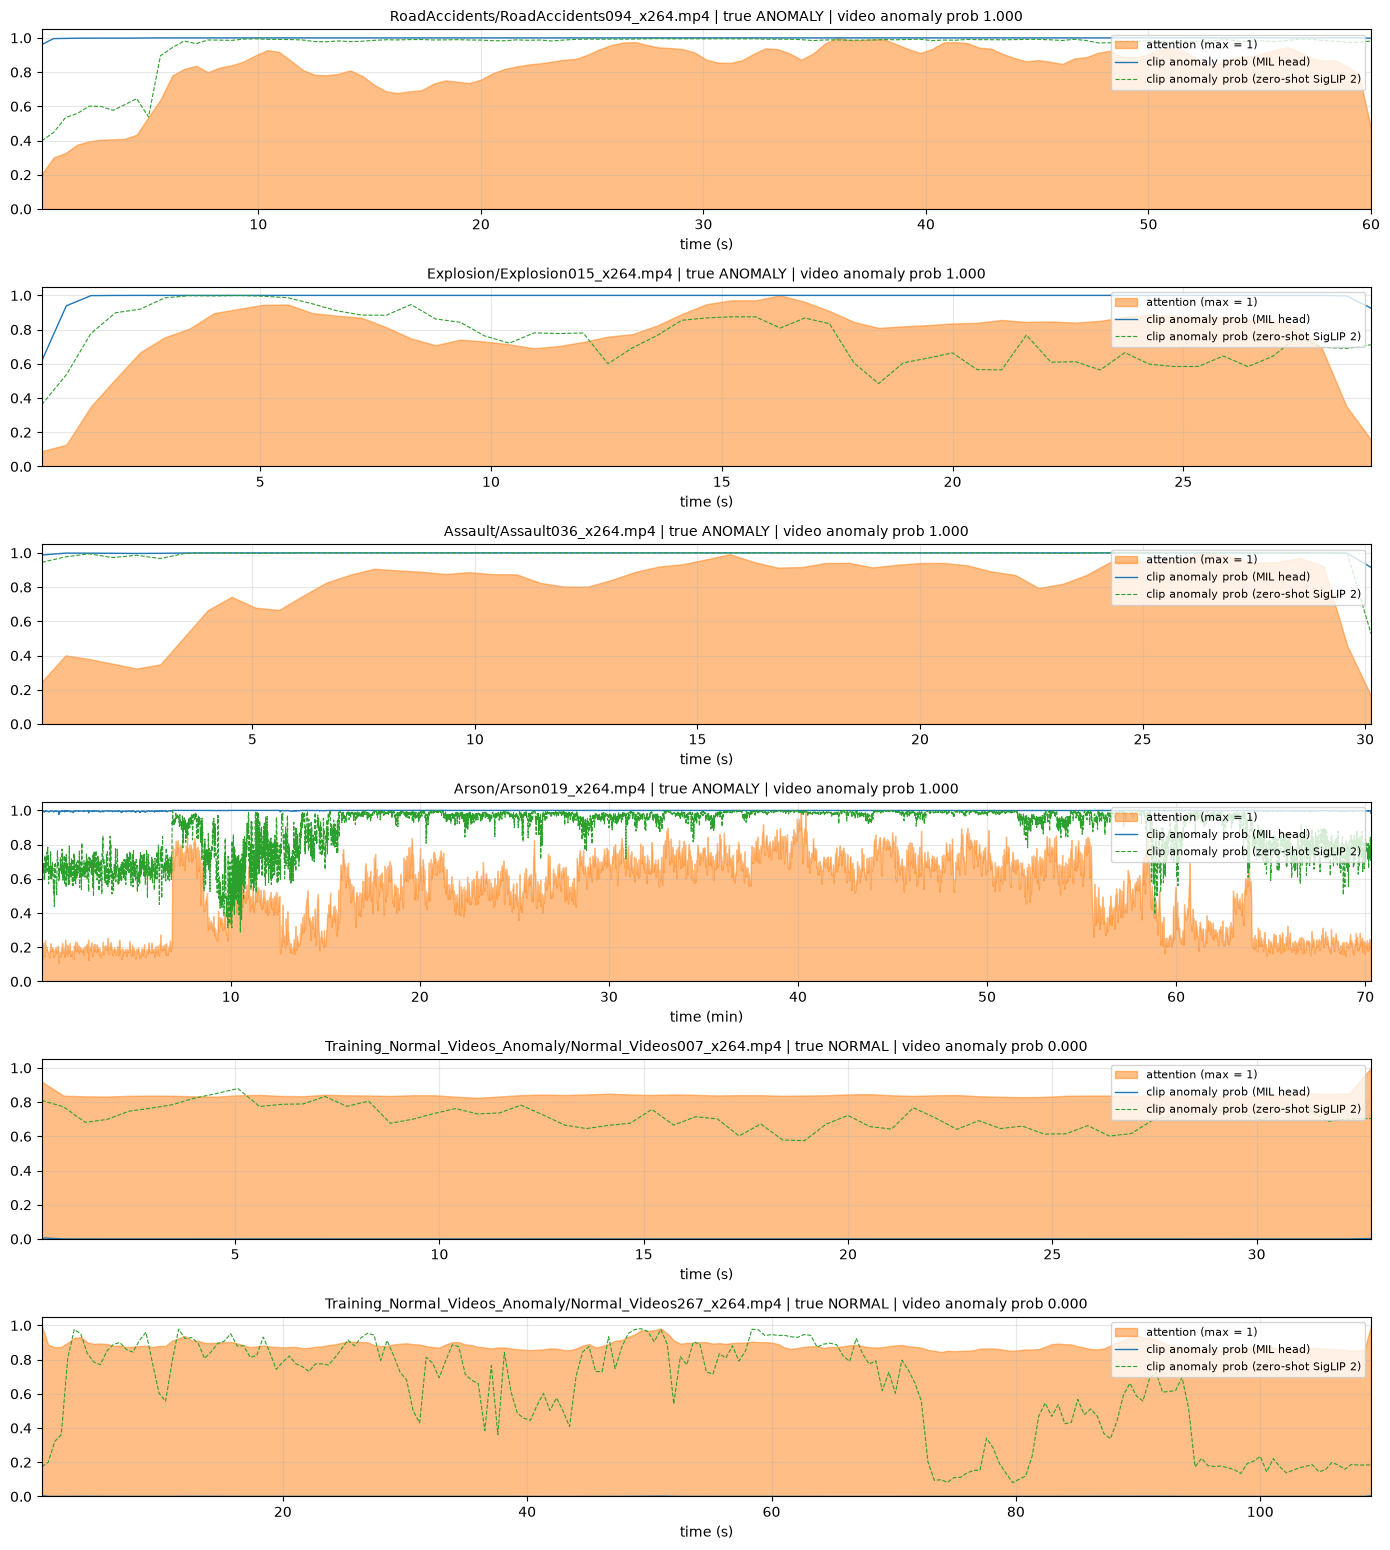

In [13]:
@torch.no_grad()
def plot_timelines(model, idx_list, save_name=None):
    fig, axes = plt.subplots(len(idx_list), 1, figsize=(14, 2.6 * len(idx_list)), squeeze=False)
    for ax, i in zip(axes[:, 0], idx_list):
        path, label = LAB_ITEMS[i]
        logit, attn, clip_logits = model(F_LAB["center"][i])
        attn = attn.cpu().numpy(); attn = attn / attn.max()
        t = (np.arange(len(attn)) * CLIP_LEN + CLIP_LEN / 2) / video_fps(path)
        unit = "min" if t[-1] > 600 else "s"
        t = t / 60 if unit == "min" else t
        ax.fill_between(t, 0, attn, color="tab:orange", alpha=0.5, label="attention (max = 1)")
        ax.plot(t, sigmoid(clip_logits.cpu().numpy()), color="tab:blue", lw=1, label="clip anomaly prob (MIL head)")
        ax.plot(t, zs_clip_probs(F_LAB["center"][i]).cpu().numpy(), color="tab:green", lw=0.8, ls="--",
                label=f"clip anomaly prob (zero-shot {ZS_BACKBONE})")
        ax.set_ylim(0, 1.05); ax.set_xlim(t[0], t[-1]); ax.set_xlabel(f"time ({unit})")
        ax.set_title(f"{os.path.relpath(path, VIDEOS_DIR)} | true {CLASSES[label]} | "
                     f"video anomaly prob {sigmoid(logit.item()):.3f}", fontsize=10)
        ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(RUNS_DIR, save_name), dpi=120)
    plt.show()


# 4 VAL anomaly videos (highest predicted probability) + 2 VAL normal videos
order = VAL_IDX[np.argsort(-val_logits_a)]
show = [i for i in order if Y_LAB[i] == 1][:4] + [i for i in order[::-1] if Y_LAB[i] == 0][:2]
plot_timelines(model_a, show, save_name="timelines_val.png")

## 10. Part B — 5-fold cross-validation over all labelled videos (TRAIN + VAL = 350 videos)

Every labelled video is in the validation fold exactly once, so the **out-of-fold** accuracy is measured on 350 videos
instead of 53. Folds are stratified by category and are the same as in notebook 03. Each fold trains for a fixed `EPOCHS` and uses the **last** epoch,
so no fold picks its checkpoint by looking at its own validation videos. This is the most honest number in the notebook.

The 5 fold models are also averaged into an ensemble for the TEST predictions.

In [14]:
cats = [category(p) for p, _ in LAB_ITEMS]
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The least populated class")   # e.g. Arson has 4 videos < 5 folds
    folds = list(skf.split(np.zeros(len(LAB_ITEMS)), cats))

oof_logits = np.zeros(len(LAB_ITEMS))
fold_models, fold_hists, fold_rows, fold_train_rows = [], [], [], []
for k, (tr, va) in enumerate(folds, 1):
    t0 = time.time()
    model_k, hist_k, _ = fit(tr, va, select_best=False, seed=SEED + k, verbose=False)
    _, _, _, oof_logits[va] = evaluate(model_k, make_criterion(tr), va)
    _, _, _, tr_logits = evaluate(model_k, make_criterion(tr), tr)           # the fold's own training videos
    y_va, y_tr = Y_LAB[va].cpu().numpy().astype(int), Y_LAB[tr].cpu().numpy().astype(int)
    fold_rows.append(metric_dict(y_va, sigmoid(oof_logits[va])))
    fold_train_rows.append(metric_dict(y_tr, sigmoid(tr_logits)))
    fold_models.append(model_k); fold_hists.append(hist_k)
    torch.save(model_k.state_dict(), os.path.join(RUNS_DIR, f"cv_fold{k}.pt"))
    print(f"fold {k}/{N_FOLDS} | train {len(tr)} val {len(va)} | train acc {fold_train_rows[-1]['accuracy']:.4f} "
          f"auc {fold_train_rows[-1]['roc_auc']:.4f} | val acc {fold_rows[-1]['accuracy']:.4f} "
          f"auc {fold_rows[-1]['roc_auc']:.4f} | {time.time()-t0:.0f}s")

fold_df = pd.concat({"TRAIN": pd.DataFrame(fold_train_rows), "VAL": pd.DataFrame(fold_rows)}, axis=1)
fold_df.index = [f"fold {k}" for k in range(1, N_FOLDS + 1)]
fold_df.loc["mean"] = fold_df.mean(); fold_df.loc["std"] = fold_df.iloc[:N_FOLDS].std()
fold_df.round(4)

fold 1/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.9143 auc 0.9801 | 35s
fold 2/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.8714 auc 0.9297 | 35s
fold 3/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.8857 auc 0.9661 | 35s
fold 4/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.9286 auc 0.9735 | 35s
fold 5/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.9714 auc 0.9959 | 35s


TRAIN                                    VAL                    \
       accuracy precision recall   f1 roc_auc accuracy precision  recall   
fold 1      1.0       1.0    1.0  1.0     1.0   0.9143    0.9459  0.8974   
fold 2      1.0       1.0    1.0  1.0     1.0   0.8714    0.8571  0.9231   
fold 3      1.0       1.0    1.0  1.0     1.0   0.8857    0.8780  0.9231   
fold 4      1.0       1.0    1.0  1.0     1.0   0.9286    0.9474  0.9231   
fold 5      1.0       1.0    1.0  1.0     1.0   0.9714    1.0000  0.9474   
mean        1.0       1.0    1.0  1.0     1.0   0.9143    0.9257  0.9228   
std         0.0       0.0    0.0  0.0     0.0   0.0391    0.0578  0.0177   

                        
            f1 roc_auc  
fold 1  0.9211  0.9801  
fold 2  0.8889  0.9297  
fold 3  0.9000  0.9661  
fold 4  0.9351  0.9735  
fold 5  0.9730  0.9959  
mean    0.9236  0.9691  
std     0.0329  0.0246

### Part B — curves averaged over the 5 folds (shaded = ± 1 std)

Epoch with lowest val loss per fold (not used): [6, 3, 4, 1, 24] | mean 7.6


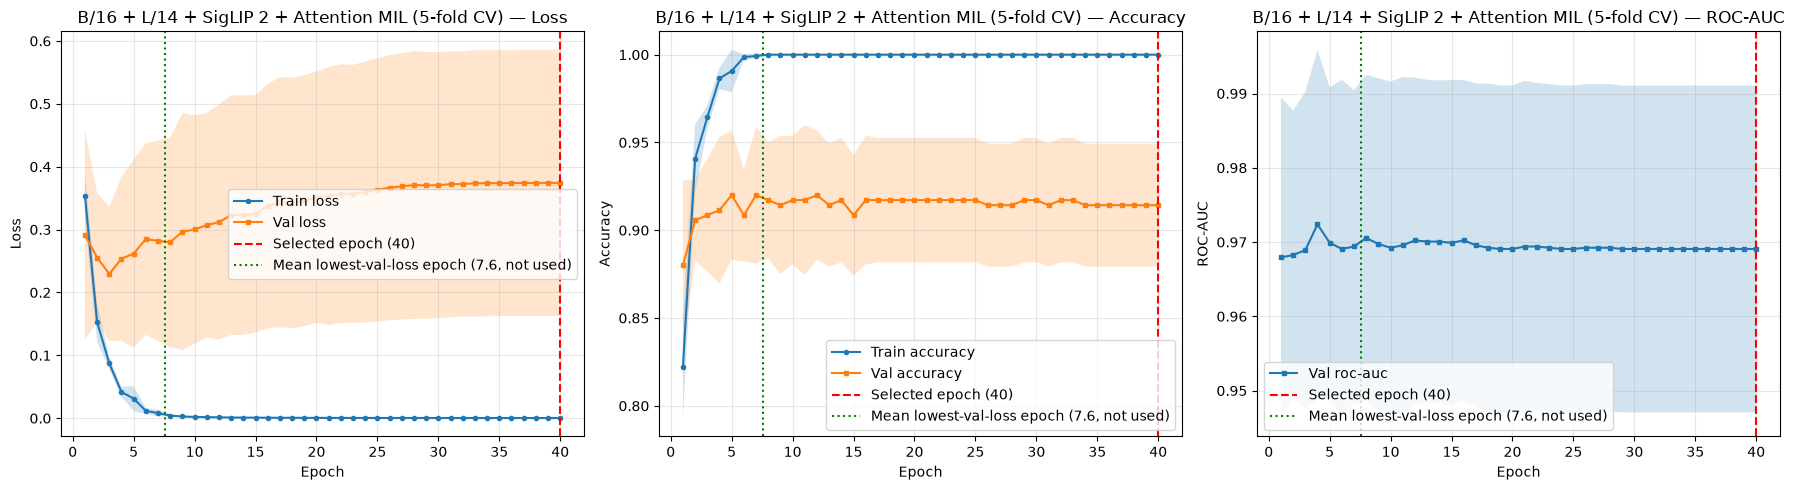

In [15]:
# CV uses the LAST epoch of every fold (select_best=False), so the selected epoch is EPOCHS for all folds.
# For information only (NOT used for selection): the epoch with the lowest val loss in each fold.
fold_best_eps = [int(np.argmin(h["val_loss"])) + 1 for h in fold_hists]
print("Epoch with lowest val loss per fold (not used):", fold_best_eps, "| mean", round(float(np.mean(fold_best_eps)), 1))
plot_history({k: [h[k] for h in fold_hists] for k in fold_hists[0]}, f"{MODEL_NAME} ({N_FOLDS}-fold CV)",
             best_ep=EPOCHS, save_name="curves_cv.png",
             extra_marks=[(float(np.mean(fold_best_eps)), f"Mean lowest-val-loss epoch ({np.mean(fold_best_eps):.1f}, not used)")])

### Part B — out-of-fold metrics on all 350 labelled videos + TEST predictions (5-fold ensemble)

===== B/16 + L/14 + SigLIP 2 + Attention MIL 5-fold CV | TRAIN+VAL (350 videos) (350 videos, whole video) =====
                            accuracy  precision  recall      f1  roc_auc
TRAIN (in-fold, fold mean)    1.0000     1.0000  1.0000  1.0000   1.0000
TRAIN+VAL (350 videos)        0.9143     0.9227  0.9227  0.9227   0.9667
              precision    recall  f1-score   support

      NORMAL     0.9038    0.9038    0.9038       156
     ANOMALY     0.9227    0.9227    0.9227       194

    accuracy                         0.9143       350
   macro avg     0.9133    0.9133    0.9133       350
weighted avg     0.9143    0.9143    0.9143       350

Per-category accuracy:
                                  acc  videos
category                                     
Abuse                           1.000      13
Arrest                          0.900      10
Arson                           1.000       4
Assault                         1.000      16
Burglary                        0.857      

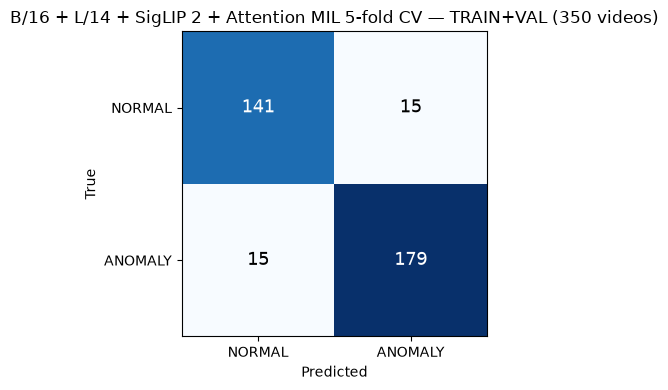

===== B/16 + L/14 + SigLIP 2 + Attention MIL 5-fold ensemble | TEST (84 videos) -> ./runs_ucf_fusionmil/test_predictions_fusionmil_cv_ensemble.csv =====
prediction
NORMAL     50
ANOMALY    34


In [16]:
cv_stage = f"{MODEL_NAME}, {N_FOLDS}-fold CV"
metrics[(cv_stage, "TRAIN (in-fold, fold mean)")] = pd.DataFrame(fold_train_rows).mean().to_dict()
metrics[(cv_stage, "TRAIN+VAL (350 videos)")] = report(
    sigmoid(oof_logits), LAB_ITEMS, "TRAIN+VAL (350 videos)", f"{MODEL_NAME} {N_FOLDS}-fold CV",
    train_m=metrics[(cv_stage, "TRAIN (in-fold, fold mean)")], train_name="TRAIN (in-fold, fold mean)")
test_pred_cv = predict_test(fold_models, f"{MODEL_NAME} {N_FOLDS}-fold ensemble", "fusionmil_cv_ensemble")
pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in LAB_ITEMS], "category": cats,     # per-video, for
              "label": Y_LAB.cpu().numpy().astype(int), "oof_logit": oof_logits}).to_csv(    # later comparisons
    os.path.join(RUNS_DIR, "cv_oof_logits.csv"), index=False)

## 11. Comparison with notebooks 01–03

The VAL rows use the same 53 videos as notebooks 01–03. The cross-validation rows use all 350 labelled videos with
notebook 03's folds, so they are not directly comparable to the VAL rows, but they are the most reliable estimate of
accuracy. The rows of the previous notebooks are read from their `metrics_summary.csv` (`PREV_RUNS` in section 1) and are
skipped if a file does not exist.

In [17]:
summary = pd.DataFrame({k: v for k, v in metrics.items() if v is not None}).T
summary.index.names = ["stage", "split"]
summary.to_csv(os.path.join(RUNS_DIR, "metrics_summary.csv"))

prev_tables = []
for tag, run_dir in PREV_RUNS.items():
    prev_csv = os.path.join(run_dir, "metrics_summary.csv")
    if os.path.exists(prev_csv):
        prev = pd.read_csv(prev_csv).set_index(["stage", "split"])
        prev.index = pd.MultiIndex.from_tuples([(f"{tag}: {s}", sp) for s, sp in prev.index], names=["stage", "split"])
        prev_tables.append(prev)
pd.concat(prev_tables + [summary]).round(4)

accuracy  \
stage                                             split                                  
01 R(2+1)D-18, sampled clips: Feature extraction  VAL                           0.6792   
01 R(2+1)D-18, sampled clips: Fine-tuned (layer4) VAL                           0.8679   
02 R(2+1)D-18, whole video: Feature extraction    VAL                           0.8113   
02 R(2+1)D-18, whole video: Fine-tuned (layer4)   VAL                           0.8679   
03 CLIP ViT-B/16: CLIP zero-shot                  TRAIN                         0.7643   
                                                  VAL                           0.8302   
03 CLIP ViT-B/16: CLIP + Attention MIL            TRAIN                         0.9832   
                                                  VAL                           0.9245   
03 CLIP ViT-B/16: CLIP + Attention MIL, 5-fold CV TRAIN (in-fold, fold mean)    1.0000   
                                                  TRAIN+VAL (350 videos)        0.8971   
CLIP B/16 zero-shot                               TRAIN                         0.7643   
                                                  VAL                           0.8302   
CLIP L/14 zero-shot                               TRAIN                         0.7576   
                                                  VAL                           0.8113   
SigLIP 2 zero-shot                                TRAIN                         0.7441   
                                                  VAL                           0.8113   
B/16 + L/14 + SigLIP 2 + Attention MIL            TRAIN                         0.9966   
                                                  VAL                           0.9434   
B/16 + L/14 + SigLIP 2 + Attention MIL, 5-fold CV TRAIN (in-fold, fold mean)    1.0000   
                                                  TRAIN+VAL (350 videos)        0.9143   

                                                                              precision  \
stage                                             split                                   
01 R(2+1)D-18, sampled clips: Feature extraction  VAL                            0.7500   
01 R(2+1)D-18, sampled clips: Fine-tuned (layer4) VAL                            0.8235   
02 R(2+1)D-18, whole video: Feature extraction    VAL                            0.7879   
02 R(2+1)D-18, whole video: Fine-tuned (layer4)   VAL                            0.8929   
03 CLIP ViT-B/16: CLIP zero-shot                  TRAIN                          0.7684   
                                                  VAL                            0.8571   
03 CLIP ViT-B/16: CLIP + Attention MIL            TRAIN                          0.9819   
                                                  VAL                            0.9630   
03 CLIP ViT-B/16: CLIP + Attention MIL, 5-fold CV TRAIN (in-fold, fold mean)     1.0000   
                                                  TRAIN+VAL (350 videos)         0.8990   
CLIP B/16 zero-shot                               TRAIN                          0.7684   
                                                  VAL                            0.8571   
CLIP L/14 zero-shot                               TRAIN                          0.7688   
                                                  VAL                            0.8276   
SigLIP 2 zero-shot                                TRAIN                          0.7633   
                                                  VAL                            0.9130   
B/16 + L/14 + SigLIP 2 + Attention MIL            TRAIN                          0.9940   
                                                  VAL                            0.9643   
B/16 + L/14 + SigLIP 2 + Attention MIL, 5-fold CV TRAIN (in-fold, fold mean)     1.0000   
                                                  TRAIN+VAL (350 videos)         0.9227   

                                                                              recall  \
stage 

### Notebook 04 vs notebook 03, video by video

Notebook 03's saved models (`runs_ucf_clipmil/clipmil_best.pt` and `cv_fold1.pt` … `cv_fold5.pt`) are re-scored on the
B/16 part of the features. The split, the folds and the B/16 features are the same, so this reproduces notebook 03's
reported numbers (checked below) and gives its prediction for every video. Both notebooks can then be compared on the
same videos:
- **Δ** = notebook 04 − notebook 03, with a 95 % bootstrap confidence interval (the videos are resampled with replacement
  10,000 times);
- **McNemar's exact test** on the videos that exactly one of the two models gets right.

A confidence interval that excludes 0, or p < 0.05, means the difference is unlikely to be luck of the split.

In [18]:
F_B16 = {v: [x[:, SLICES["CLIP B/16"]] for x in F_LAB[v]] for v in VIEWS}   # notebook 03's features (views, no copy)


@torch.no_grad()
def nb03_logits(state_dict, idx):
    m = AttentionMIL(d_in=DIMS["CLIP B/16"]).to(device)
    m.load_state_dict(state_dict)
    return video_logits(m.eval(), F_B16, idx).cpu().numpy()


val_logits_03 = nb03_logits(torch.load(os.path.join(NB03_RUNS, "clipmil_best.pt"), map_location=device)["model"], VAL_IDX)
oof_logits_03 = np.zeros(len(LAB_ITEMS))
for k, (_, va) in enumerate(folds, 1):
    oof_logits_03[va] = nb03_logits(torch.load(os.path.join(NB03_RUNS, f"cv_fold{k}.pt"), map_location=device), va)

y_lab = Y_LAB.cpu().numpy().astype(int)
ref03 = pd.read_csv(os.path.join(NB03_RUNS, "metrics_summary.csv")).set_index(["stage", "split"])
for logits, idx, row in [(val_logits_03, VAL_IDX, ("CLIP + Attention MIL", "VAL")),
                         (oof_logits_03, np.arange(len(LAB_ITEMS)),
                          ("CLIP + Attention MIL, 5-fold CV", "TRAIN+VAL (350 videos)"))]:
    m = metric_dict(y_lab[idx], sigmoid(logits))
    assert all(abs(m[k] - ref03.loc[row, k]) < 1e-3 for k in m), f"notebook 03 re-scored differs from its csv: {row}"
print("notebook 03 re-scored from its saved models: identical to runs_ucf_clipmil/metrics_summary.csv")


def auc_rows(y, s):
    """ROC-AUC of every row of the (B, n) labels y and scores s (Mann-Whitney U; ties get average ranks)."""
    r = rankdata(s, axis=1)
    n1 = y.sum(1); n0 = y.shape[1] - n1
    return ((r * y).sum(1) - n1 * (n1 + 1) / 2) / (n1 * n0)


def paired_test(y, logits_04, logits_03, n_boot=10_000, seed=SEED):
    """Δ accuracy and Δ ROC-AUC (04 - 03) on the same videos with 95 % bootstrap CIs, and McNemar's exact test."""
    ok_04, ok_03 = (logits_04 >= 0) == y, (logits_03 >= 0) == y          # probability >= 0.5 <=> logit >= 0
    b = np.random.default_rng(seed).integers(0, len(y), (n_boot, len(y)))
    d_acc = ok_04[b].mean(1) - ok_03[b].mean(1)
    with np.errstate(invalid="ignore", divide="ignore"):                  # a resample with one class has no AUC
        d_auc = auc_rows(y[b], logits_04[b]) - auc_rows(y[b], logits_03[b])
    only_04, only_03 = int((ok_04 & ~ok_03).sum()), int((ok_03 & ~ok_04).sum())
    ci = lambda d: f"[{np.nanpercentile(d, 2.5):+.3f}, {np.nanpercentile(d, 97.5):+.3f}]"
    auc_03, auc_04 = roc_auc_score(y, logits_03), roc_auc_score(y, logits_04)
    return {"videos": len(y), "accuracy 03": ok_03.mean(), "accuracy 04": ok_04.mean(),
            "Δ accuracy": ok_04.mean() - ok_03.mean(), "Δ accuracy 95% CI": ci(d_acc),
            "ROC-AUC 03": auc_03, "ROC-AUC 04": auc_04, "Δ ROC-AUC": auc_04 - auc_03, "Δ ROC-AUC 95% CI": ci(d_auc),
            "only 04 right": only_04, "only 03 right": only_03,
            "McNemar p": binomtest(only_04, only_04 + only_03).pvalue if only_04 + only_03 else 1.0}


paired = pd.DataFrame.from_dict({
    "Part A: same TRAIN/VAL split (53 VAL videos)": paired_test(y_lab[VAL_IDX], val_logits_a, val_logits_03),
    f"Part B: {N_FOLDS}-fold CV, same folds (350 videos)": paired_test(y_lab, oof_logits, oof_logits_03)},
    orient="index")
paired.to_csv(os.path.join(RUNS_DIR, "paired_vs_03.csv"))
paired.round(4)

notebook 03 re-scored from its saved models: identical to runs_ucf_clipmil/metrics_summary.csv


,videos,accuracy 03,accuracy 04,Δ accuracy,Δ accuracy 95% CI,ROC-AUC 03,ROC-AUC 04,Δ ROC-AUC,Δ ROC-AUC 95% CI,only 04 right,only 03 right,McNemar p
Part A: same TRAIN/VAL split (53 VAL videos),53,0.9245,0.9434,0.0189,"[-0.038, +0.094]",0.9655,0.9856,0.0201,"[+0.000, +0.051]",2,1,1.0000
"Part B: 5-fold CV, same folds (350 videos)",350,0.8971,0.9143,0.0171,"[-0.009, +0.043]",0.9584,0.9667,0.0083,"[-0.002, +0.019]",14,8,0.2863


### What does each backbone add? Part B with every subset of the three backbones

The same 5-fold cross-validation as Part B (same folds, same seeds, 40 epochs, last epoch, threshold 0.5), with the MIL
head trained on the features of each subset of the backbones. "CLIP B/16" alone is notebook 03 (its saved fold models,
re-scored above) and "CLIP B/16 + CLIP L/14 + SigLIP 2" is Part B of this notebook. The model of this notebook was fixed
before these numbers were computed: they explain where its accuracy comes from, they were not used to choose it.

`wrong` is the number of the 350 videos a subset gets wrong, and `also wrong in 03` how many of those notebook 03 also
gets wrong. The lower `also wrong in 03` is relative to `wrong`, the more the subset's mistakes differ from notebook 03's.

In [19]:
def subset_feats(feats, names):
    """The clip features of the backbones `names` only (their columns of the fused features)."""
    cols = torch.cat([torch.arange(SLICES[n].start, SLICES[n].stop) for n in names]).to(device)
    return {v: [x[:, cols] for x in feats[v]] for v in VIEWS}


ablation_logits = {}
for r in range(1, len(BACKBONES) + 1):
    for names in combinations(BACKBONES, r):
        tag = " + ".join(names)
        if names == ("CLIP B/16",):
            ablation_logits[tag] = oof_logits_03                         # notebook 03
        elif len(names) == len(BACKBONES):
            ablation_logits[tag] = oof_logits                            # this notebook, Part B
        else:
            t0, feats, logits = time.time(), subset_feats(F_LAB, names), np.zeros(len(LAB_ITEMS))
            for k, (tr, va) in enumerate(folds, 1):
                model_k, _, _ = fit(tr, va, select_best=False, seed=SEED + k, verbose=False, feats=feats)
                _, _, _, logits[va] = evaluate(model_k, make_criterion(tr), va, feats)
            ablation_logits[tag] = logits
            del feats
            print(f"{tag}: {N_FOLDS}-fold CV done in {time.time() - t0:.0f}s")

ablation = pd.DataFrame({tag: metric_dict(y_lab, sigmoid(lg)) for tag, lg in ablation_logits.items()}).T
ablation.insert(0, "dim", [sum(DIMS[n] for n in tag.split(" + ")) for tag in ablation.index])
ablation["Δ accuracy vs 03"] = ablation["accuracy"] - ablation.loc["CLIP B/16", "accuracy"]
wrong = {tag: (lg >= 0) != y_lab for tag, lg in ablation_logits.items()}         # probability >= 0.5 <=> logit >= 0
ablation["wrong"] = [int(wrong[tag].sum()) for tag in ablation.index]
ablation["also wrong in 03"] = [int((wrong[tag] & wrong["CLIP B/16"]).sum()) for tag in ablation.index]
ablation.to_csv(os.path.join(RUNS_DIR, "backbone_ablation_cv.csv"))
pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in LAB_ITEMS], "label": y_lab, **ablation_logits}).to_csv(
    os.path.join(RUNS_DIR, "backbone_ablation_oof_logits.csv"), index=False)              # per video, for later comparisons
ablation.round(4)

CLIP L/14: 5-fold CV done in 149s
SigLIP 2: 5-fold CV done in 154s
CLIP B/16 + CLIP L/14: 5-fold CV done in 157s
CLIP B/16 + SigLIP 2: 5-fold CV done in 164s
CLIP L/14 + SigLIP 2: 5-fold CV done in 169s


,dim,accuracy,precision,recall,f1,roc_auc,Δ accuracy vs 03,wrong,also wrong in 03
CLIP B/16,512,0.8971,0.8990,0.9175,0.9082,0.9584,0.0000,36,36
CLIP L/14,768,0.9029,0.9167,0.9072,0.9119,0.9589,0.0057,34,24
SigLIP 2,1152,0.8943,0.8985,0.9124,0.9054,0.9609,-0.0029,37,21
CLIP B/16 + CLIP L/14,1280,0.9171,0.9275,0.9227,0.9251,0.9653,0.0200,29,26
CLIP B/16 + SigLIP 2,1664,0.9086,0.9175,0.9175,0.9175,0.9649,0.0114,32,24
CLIP L/14 + SigLIP 2,1920,0.9086,0.9133,0.9227,0.9179,0.9656,0.0114,32,20
CLIP B/16 + CLIP L/14 + SigLIP 2,2432,0.9143,0.9227,0.9227,0.9227,0.9667,0.0171,30,22


### Accuracy, F1 and ROC-AUC of all models on the two evaluation sets

Blue: the model of this notebook. Orange: notebook 03. Gray: every other model (notebooks 01–02, the zero-shot baselines,
the backbone subsets). The x-axes do not start at 0.

In [ ]:

C_04, C_03, C_OTHER = "#2a78d6", "#eb6834", "#898781"

# Metrics included in comparison tables
PLOT_METRICS = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "roc_auc": "ROC-AUC"
}


def comparison_table(table, title, row_04, row_03, save_name):
    """Comparison table highlighting notebook 04, notebook 03, and other models."""

    display_table = table.copy()
    display_table.index.name = "Model"

    display_table = display_table.rename(columns=PLOT_METRICS)
    display_table = display_table.reset_index()
    display_table = display_table.round(3)

    def highlight_rows(row):
        model = row["Model"]

        if model in (row_04, row_03):
            return ["font-weight: bold"] * len(row)

        return [""] * len(row)

    styled = (
        display_table.style
        .apply(highlight_rows, axis=1)
        .set_caption(title)
        .format({
            "Accuracy": "{:.3f}",
            "Precision": "{:.3f}",
            "Recall": "{:.3f}",
            "F1": "{:.3f}",
            "ROC-AUC": "{:.3f}"
        })
        .set_properties(**{
            "text-align": "center",
            "padding": "8px"
        })
        .set_table_styles([
            {"selector": "th", "props": [
                ("background-color", "#f0f0f0"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]},
            {"selector": "caption", "props": [
                ("caption-side", "top"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding", "10px")
            ]}
        ])
    )

    display(styled)

    # Save comparison table as CSV
    display_table.to_csv(
        os.path.join(RUNS_DIR, save_name.replace(".png", ".csv")),
        index=False
    )


# ============================================================
# VAL-53: Validation comparison (53 videos)
# ============================================================

val_rows = {}

# Collect VAL metrics from previous notebooks (01-03)
for tag, run_dir in PREV_RUNS.items():

    prev_csv = os.path.join(run_dir, "metrics_summary.csv")

    if os.path.exists(prev_csv):

        prev_df = pd.read_csv(prev_csv)

        for _, r in prev_df.iterrows():

            if r["split"] == "VAL":

                val_rows[f"{tag}: {r['stage']}"] = (
                    r[list(PLOT_METRICS)].astype(float)
                )


# Collect VAL metrics from notebook 04
for (stage, split), m in metrics.items():

    if split == "VAL" and stage != "CLIP B/16 zero-shot":

        val_rows[f"04: {stage}"] = (
            pd.Series(m)[list(PLOT_METRICS)].astype(float)
        )


# Generate VAL-53 comparison table
comparison_table(
    pd.DataFrame(val_rows).T,
    "VAL-53: the 53 VAL videos of the TRAIN/VAL split shared by notebooks 01-04",
    row_04=f"04: {MODEL_NAME}",
    row_03="03 CLIP ViT-B/16: CLIP + Attention MIL",
    save_name="comparison_val53.png"
)


# ============================================================
# CV-350: Cross-validation comparison (350 videos)
# ============================================================

all_three = " + ".join(BACKBONES)

cv_table = ablation[list(PLOT_METRICS)].rename(
    index={
        "CLIP B/16": "CLIP B/16 (notebook 03)",
        all_three: f"{all_three} (notebook 04)"
    }
)


# Generate CV-350 comparison table
comparison_table(
    cv_table,
    "CV-350: out-of-fold predictions on all 350 labelled videos (notebook 03's folds), MIL head on each subset of the backbones",
    row_04=f"{all_three} (notebook 04)",
    row_03="CLIP B/16 (notebook 03)",
    save_name="comparison_cv350.png"
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,"01 R(2+1)D-18, sampled clips: Feature extraction",0.679,0.750,0.621,0.679,0.819
1,"01 R(2+1)D-18, sampled clips: Fine-tuned (layer4)",0.868,0.824,0.966,0.889,0.943
2,"02 R(2+1)D-18, whole video: Feature extraction",0.811,0.788,0.897,0.839,0.841
3,"02 R(2+1)D-18, whole video: Fine-tuned (layer4)",0.868,0.893,0.862,0.877,0.938
4,03 CLIP ViT-B/16: CLIP zero-shot,0.830,0.857,0.828,0.842,0.826
5,03 CLIP ViT-B/16: CLIP + Attention MIL,0.925,0.963,0.897,0.929,0.966
6,04: CLIP L/14 zero-shot,0.811,0.828,0.828,0.828,0.852
7,04: SigLIP 2 zero-shot,0.811,0.913,0.724,0.808,0.859
8,04: B/16 + L/14 + SigLIP 2 + Attention MIL,0.943,0.964,0.931,0.947,0.986


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,CLIP B/16 (notebook 03),0.897,0.899,0.918,0.908,0.958
1,CLIP L/14,0.903,0.917,0.907,0.912,0.959
2,SigLIP 2,0.894,0.898,0.912,0.905,0.961
3,CLIP B/16 + CLIP L/14,0.917,0.927,0.923,0.925,0.965
4,CLIP B/16 + SigLIP 2,0.909,0.918,0.918,0.918,0.965
5,CLIP L/14 + SigLIP 2,0.909,0.913,0.923,0.918,0.966
6,CLIP B/16 + CLIP L/14 + SigLIP 2 (notebook 04),0.914,0.923,0.923,0.923,0.967
